In [3]:
import pickle
import random
import re
import string

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sparse
import seaborn as sns
from scipy.sparse.linalg import svds
from tqdm import tqdm

#### Utility Functions

In [4]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def save_models(word_freqs, Vsvd, Vw2v, 
    word2index = None, index2word = None, losses_w2v = None):

    '''
    Save all the appropriate data. We are expecting the variables
    shown below.
    '''
    data = {
        'word_freqs': word_freqs,
        'Vsvd': Vsvd,
        'Vw2v': Vw2v,
        'word2index': word2index,
        'index2word': index2word,
        'losses_w2v': losses_w2v,
    }

    with open('assignment5.pkl', 'wb') as f:
        pickle.dump(data, f)

#### Print Top K Word Vectors from Vectors Matrix

In [5]:
def print_topk(word, V, word2index, index2word, k=10):
    '''
    Args:
    - word: a string, e.g., "neural" to look up
    - V: a matrix of vectors, size num_words x embedding_size
    - word2index: dictionary of {word: index}
    - index2word: dictionary of {index: word}
    - k: number of words to print
    '''
    print("Top ", k, " words closest to ", word, ":")
    
    # Normalize the vectors
    V_normalized = V / np.linalg.norm(V, axis=1, keepdims=True)
    
    correlations = V_normalized[word2index[word]] @ V_normalized.T
    topk_indices = np.argsort(correlations)[-k:][::-1]
    for index in topk_indices:
    print(index2word[index], correlations[index])

### Question 1

In [32]:
def process_data(filename, min_cnt, max_cnt, min_words = 5, min_letters = 3):
    '''
    Preprocesses and builds the distribution of words in sorted order
    (from maximum occurrence to minimum occurrence) after reading the
    file. Preprocessing will include filtering out:
    * words that have non-letters in them,
    * words that are too short (under minletters)

    Arguments:
        - filename: name of file
        - min_cnt: min occurrence of words to include
        - max_cnt: max occurrence of words to include
        - min_words: minimum number of words in a title after word filtering
        - min_letters: min length of words to include (3)

    Returns:
        - word_freqs: A sorted (max to min) list of tuples of form -

            [(word1, count1), (wordN, countN), ... (wordN, countN)]

        - dataset: A list of strings with OOV words removed -

            ["this is title 1", "this is title 2", ...]
    '''
    from collections import Counter
    with open(filename, "r", encoding="utf-8") as f:
        titles = f.read().split("\n")

    word_counts = Counter(w.lower() for title in titles
                          for w in re.findall(r"[a-zA-Z]+", title)
                          if len(w) >= min_letters)
    for word in [w for w, c in word_counts.items() if not min_cnt <= c <= max_cnt]:
        del word_counts[word]
    word_freqs = word_counts.most_common()

    dataset = []
    for title in titles:
        title = title.lower()
        words = [w for w in re.findall(r"[a-zA-Z]+", title) if w in word_counts]
        if len(words) >= min_words:
            dataset.append(" ".join(words))
    
    return word_freqs, dataset

def process_data_test():
    
    data_test = [
      "A Case for Neural Networks Models: Deeper is Better",
      "Large Language models: Transformers require Data",
      "A United Framework of large language models",
      "A Survey of Neural Translation Models for Large Language Models"
    ]
    
    with open("test.txt", 'w') as f:
    for title in data_test:
      f.write(title + '\n')
    
    word_freqs, filtered_dataset = process_data(
      "test.txt", 2, 100, min_words=4, min_letters=4)
    
    # Expected data after filtering should have the properties that:
    #   - Words appear at least twice, (i.e., models, large, language, neural)
    #   - There are at least four words in the title
    #   - Each word is at least four letters long
    expected_word_freqs = [
      ('models', 5), ('large', 3), ('language', 3), ('neural', 2)
    ]
    
    expected_filtered_dataset = ['neural models large language models']
    
    assert word_freqs == expected_word_freqs, "Your word frequencies are incorrect. " \
    "Expected:\n" + str(expected_word_freqs) + "\nReceived:\n" + str(word_freqs)
    assert filtered_dataset == expected_filtered_dataset, "Your filtered dataset is incorrect. " \
    "Expected:\n" + str(expected_filtered_dataset) + "\nReceived:\n" + str(filtered_dataset)
    
    print("\nprocess_data: \033[1;32mtests OK.\033[0m")

In [33]:
process_data_test()


process_data: tests OK.


### Question 2.1

In [44]:
def create_adjacency(dataset, word2index, win = 10):
    '''
    Builds an adjacency matrix based on word co-occurrence within a window.

    Args:
        - dataset: List of processed titles
        - word2index: Dictionary mapping word to index
        - win: The window size for co-occurrence.

    Returns:
        - adjacency_matrix: A NumPy array representing the adjacency matrix.
    '''
    V = len(word2index)
    A = np.zeros((V, V), dtype=np.float32)
    for title in dataset:
        idx = [word2index[w] for w in title.split() if w in word2index]
        for i in range(len(idx)):
            for j in range(i + 1, min(i + win // 2 + 1, len(idx))):
                A[idx[i], idx[j]] += 1
                A[idx[j], idx[i]] += 1
    
    return A

def create_adjacency_test():
    
    # Test file
    data_test = [
      "A Case for Neural Networks Models: Deeper is Better",
      "Large Language models: Transformers require Data",
      "A United Framework of Language Models"
    ]
    with open("test.txt", 'w') as f:
    for title in data_test:
      f.write(title + '\n')
    
    # Obtain word frequencies and dataset
    word_freqs, filtered_dataset = process_data(
      "test.txt", 1, 100, min_words=3, min_letters=3)
    
    # Create word2index to use in calculating adjacency matrix
    word2index = {word[0]: i for i, word in enumerate(word_freqs)}
    
    # Run your code
    adjacency_matrix = create_adjacency(filtered_dataset, word2index, win=5)
    
    # Since we have the option to have counts or boolean, just check boolean
    adjacency_matrix = np.array((adjacency_matrix > 0).astype(int))
    
    # Expected adjacency matrix
    adjacency_matrix_expected = np.array([
    [ 0,1,0,0,1,1,1,1,1,1,1,0,0,1 ],
    [ 1,0,0,0,0,0,0,0,1,1,0,0,1,1 ],
    [ 0,0,0,1,1,0,0,0,0,0,0,0,0,0 ],
    [ 0,0,1,0,1,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,1,1,0,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,0,1,1,0,1,0,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,1,0,1,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,0,1,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,1,1,0,0 ],
    [ 1,0,0,0,0,0,0,0,0,1,0,1,0,0 ],
    [ 0,0,0,0,0,0,0,0,0,1,1,0,0,0 ],
    [ 0,1,0,0,0,0,0,0,0,0,0,0,0,1 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,1,0 ]])
    
    # There should be no difference
    difference = sum(sum( abs(adjacency_matrix - adjacency_matrix_expected)))
    assert difference == 0, "Your adjacency matrix is incorrect. \nExpected:\n" + \
    str(adjacency_matrix_expected) + "\nReceived:\n" + str(adjacency_matrix) + \
    "\n\nDifference:" + str(difference)
    
    # Tests OK
    print("create_adjacency: \033[1;32mtests OK.\033[0m")

In [45]:
create_adjacency_test()

create_adjacency: tests OK.


### Question 2.2

In [48]:
import pandas as pd


def train_svd(adjacency_matrix, min_sv_index = 3, max_sv_index = 103):
    """
    Creates an embedding space using SVD on the adjacency matrix. The two parameters
    min_sv_index and max_sv_index provide the embedding size, where

        embedding_size = max_sv_index - min_sv_index.

    So, if s is a vector of all the singular values sorted from largest to smallest,
    then the embedding matrix will use the vectors corresponding to

        singular_values = s[min_sv_index:max_sv_index]

    Args:
        - adjacency_matrix: The adjacency matrix.
        - min_sv_index: The index of the largest singular value to use.
        - max_sv_index: The index of the largest singular value to use

    Returns:
        - A NumPy array representing the embedding space (num_words x embedding_dim)
    """
    U, s, _ = svds(adjacency_matrix, k=max_sv_index + 1)
    U, s = U[:, ::-1], s[::-1] # svds already returns values in ascending order, so just reversing
    
    return U[:, min_sv_index:max_sv_index + 1] * s[min_sv_index:max_sv_index + 1]

def train_svd_test():
    
    vocabulary = ['models', 'language', 'case', 'for', 'neural', 'networks',
                'deeper', 'better', 'large', 'transformers', 'require', 'data',
                'united', 'framework']
    
    adjacency_matrix = np.array([
    [ 0,1,0,0,1,1,1,1,1,1,1,0,0,1 ],
    [ 1,0,0,0,0,0,0,0,1,1,0,0,1,1 ],
    [ 0,0,0,1,1,0,0,0,0,0,0,0,0,0 ],
    [ 0,0,1,0,1,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,1,1,0,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,0,1,1,0,1,0,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,1,0,1,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,0,1,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,1,1,0,0 ],
    [ 1,0,0,0,0,0,0,0,0,1,0,1,0,0 ],
    [ 0,0,0,0,0,0,0,0,0,1,1,0,0,0 ],
    [ 0,1,0,0,0,0,0,0,0,0,0,0,0,1 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,1,0 ]]).astype(np.float32)
    
    # Run your code
    U_fast = train_svd(adjacency_matrix, min_sv_index = 1, max_sv_index=8)
    
    word_vectors = dict()
    for i, word in enumerate(vocabulary):
    word_vectors[word] = U_fast[i]
    
    # Check the sizes of the matrices
    assert adjacency_matrix.shape == (14, 14)
    assert U_fast.shape == (14, 8)
    
    print("train_svd: \033[1;32mtests OK.\033[0m")

In [49]:
train_svd_test()

train_svd: tests OK.


### Question 3.1

In [51]:
def sample_w2v(data, word2index, neg_samples=5, win=10, sampling_distro=None):
    '''
    Randomly samples a title and a window within that title, returning
    one-hot and multi-hot vectors.

    Args:
        - data: A list of preprocessed titles.
        - word2index: A dictionary of words and their indices
        - neg_samples: Number of negative samples
        - win: The size of the context window.
        - sampling_distro: Sampling distribution of the words, likely Zipfian

    Returns:
        - wi: target vector index
        - wo: context vector index
        - Wn: negative vectors index
    '''
    sample_title = data[np.random.randint(len(data))]     
    idx = [word2index[w] for w in sample_title.split()]

    i = np.random.randint(len(idx))
    half = max(1, win // 2)
    context = [j for j in range(max(0, i - half), min(len(idx), i + half + 1)) if j != i]

    wi = idx[i]
    wo = idx[np.random.choice(context)]
    Wn = np.random.choice(len(word2index), size=neg_samples, p=sampling_distro)

    return wi, wo, Wn

### Question 3.3

In [53]:
def w2vgrads( vi, vo, Vns ):
    """
    This function implements the gradient for all vectors in
    input matrix Vi and output matrix Vo.
    
    Args:
    - vi:  Vector of shape (d,), a sample in the input word
         vector matrix
    - vo:  Vector of shape (d,), a positive sample in the output
         word vector matrix
    - Vns: Vector of shape (k, d), k negative samples in the
         output word vector matrix
    
    Returns:
    - dvi, dvo, dVns: the gradients of J with respect to vi
                    and vo.
    """
    so = sigmoid(vo @ vi)
    sn = sigmoid(Vns @ vi)

    dvi = (so - 1) * vo + sn @ Vns
    dvo = (so - 1) * vi
    dVns = np.outer(sn, vi)
    return dvi, dvo, dVns

def w2vgrads_test():
    
    vi = np.array([1., 0., 0., 0.])
    vo = np.array([0., 1., 0., 0.])
    
    Vns = np.array([
      [0., 0., 1., 0.],
      [0., 0., 0., 1.],
      [1., 0., 0., 0.]
    ])
    
    dvi, dvo, dVns = w2vgrads(vi, vo, Vns)
    
    expected_dvi = np.array([0.73105858, -0.5, 0.5, 0.5])
    expected_dvo = np.array([-0.5, -0. , -0. , -0. ])
    expected_dVns = np.array([[0.5       , 0.        , 0.        , 0.        ],
       [0.5       , 0.        , 0.        , 0.        ],
       [0.73105858, 0.        , 0.        , 0.        ]])
    
    # Added assertions to check the results
    assert np.allclose(dvi, expected_dvi), "dvi calculation is incorrect"
    assert np.allclose(dvo, expected_dvo), "dvo calculation is incorrect"
    assert np.allclose(dVns, expected_dVns), "dVns calculation is incorrect"
    
    print("w2vgrads: \033[1;32mtests OK.\033[0m")

In [54]:
w2vgrads_test()

w2vgrads: tests OK.


### Question 3.4

In [56]:
def train_w2v(dataset, word2index, word_freqs, iters = 1e6, negsamps = 5,
              win = 5, embedding_dim = 100, learning_rate=0.01,
              vectors = None):
    """
    Creates an embedding space using SVD on the adjacency matrix.

    Args:
        - dataset: A list of preprocessed titles.
        - word2index: Dictinoary assigning word to index
        - word_freqs: A list of tuples of (word, count)
        - iters: Number of iterations to run for (default 1e6)
        - negsamps: Number of negative samples
        - win: The size of the context window for sampling.
        - embedding_dim: The desired dimensionality of the embedding space.
        - learning_rate: Learning rate or any other DNN params with defaults.
                       The autograder won't touch this.

    Returns:
        - Vw2v: a tuple with two numpy arrays of size N words x d dimensions
        - List of losses (to print out)
    """
    V = len(word2index)

    # Init Vi and Vo matrices unless vectors matrix already provided
    if not vectors:
        Vi = (np.random.rand(V, embedding_dim) - 0.5) / embedding_dim
        Vo = np.zeros((V, embedding_dim))
    else:
        Vi = Vo = vectors

    # Noise distribution
    counts = np.zeros(V)
    for w, c in word_freqs:
        counts[word2index[w]] = c
    sampling_distro = counts ** 0.75
    sampling_distro /= sampling_distro.sum()

    losses = []
    # SGD loop
    for _ in range(int(iters)):
          wi, wo, Wn = sample_w2v(dataset, word2index, negsamps, win, sampling_distro)
          vi, vo, Vns = Vi[wi], Vo[wo], Vo[Wn]

          losses.append(-np.log(sigmoid(vo @ vi)) - np.log(sigmoid(-(Vns @ vi))).sum())

          dvi, dvo, dVns = w2vgrads(vi, vo, Vns)
          Vi[wi] -= learning_rate * dvi
          Vo[wo] -= learning_rate * dvo
          np.subtract.at(Vo, Wn, learning_rate * dVns)   # handles repeated negatives

    return (Vi, Vo), losses

def train_w2v_test():
    vocabulary = ['models', 'language', 'case', 'for', 'neural', 'networks',
                'deeper', 'better', 'large', 'transformers', 'require', 'data',
                'united', 'framework']
    
    word2index = {word: i for i, word in enumerate(vocabulary)}
    
    data_test = [
      "A Case for Neural Networks Models: Deeper is Better",
      "Large Language models: Transformers require Data",
      "A United Framework of Language Models"
    ]
    with open("test.txt", 'w') as f:
        for title in data_test:
          f.write(title + '\n')
    
    word_freqs, filtered_dataset = process_data(
      "test.txt", 1, 100, min_words=3, min_letters=3)
    
    (Vw2v_Vi, Vw2v_Vo), losses = train_w2v(filtered_dataset, word2index, word_freqs,
                           iters = 1000, negsamps = 5, win = 3,
                           embedding_dim = 100, learning_rate=0.01)
    
    assert Vw2v_Vi.shape == (14, 100)
    assert Vw2v_Vo.shape == (14, 100)
    assert len(losses) == 1000

In [58]:
train_w2v_test()

## Main Function


process_data: tests OK.
create_adjacency: tests OK.
train_svd: tests OK.
w2vgrads: tests OK.


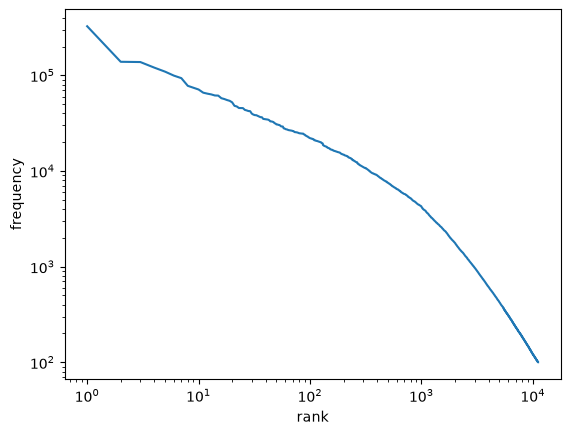

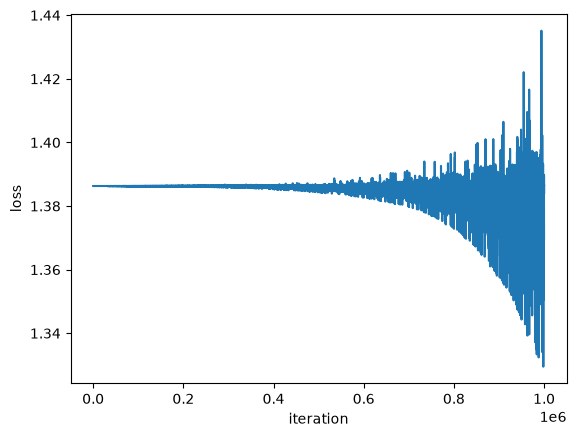

Nearest neighbors of 'neural'
Top  10  words closest to  neural :
neural 1.0
multiplex 0.9330724
capsule 0.9227795
regulatory 0.91713095
arnold 0.91264546
multihop 0.8922926
vehicular 0.8911211
relu 0.8882744
wireless 0.8867403
neuronal 0.88014984
Top  10  words closest to  neural :
neural 0.9999999999999998
graph 0.8535556606345561
learning 0.8322024412627562
based 0.821492047716765
convolutional 0.8062276215804233
using 0.781707206615352
network 0.7704559537319637
image 0.7514999763708903
deep 0.7448076269871893
detection 0.7392665675185642
Nearest neighbors of 'machine'
Top  10  words closest to  machine :
machine 1.0000001
federated 0.9904641
continual 0.9874404
imitation 0.98303425
dictionary 0.97682726
curriculum 0.9761182
meta 0.9756876
multitask 0.9752226
incremental 0.9664282
lifelong 0.9628206
Top  10  words closest to  machine :
machine 1.0000000000000002
deep 0.9540344251184989
reinforcement 0.9465000707427176
based 0.8610883479528872
approach 0.8082639758024854
using 0.804

In [61]:
if __name__ == '__main__':
    # Run unit tests
    process_data_test()
    create_adjacency_test()
    train_svd_test()
    w2vgrads_test()
    train_w2v_test()
    
    # Process "arxiv_titles.txt". Download from:
    # https://course.ccs.neu.edu/cs6120f26/data/arxiv/arxiv_titles.txt
    word_freqs, filtered_dataset = process_data("arxiv_titles.txt", 100, 1e10, min_words=5, min_letters=4)

    # Plot Zipfian distribution of word_freqs
    counts = [c for _, c in word_freqs]
    ranks = range(1, len(counts) + 1)
    
    plt.loglog(ranks, counts)
    plt.xlabel("rank")
    plt.ylabel("frequency")
    plt.show()

    # Create the appropriate data structures from word_freqs variable.
    vocabulary = [tuple[0] for tuple in word_freqs]
    word2index = {word: i for i, word in enumerate(vocabulary)}
    index2word = {i: word for i, word in enumerate(vocabulary)}

    # Process with SVD
    adjacency_matrix = create_adjacency(filtered_dataset, word2index, win=5)
    Vsvd = train_svd(adjacency_matrix, min_sv_index = 1, max_sv_index=100)

    # Process with Word2Vec
    Vw2v, losses = train_w2v(filtered_dataset, word2index, word_freqs, iters = 1e6, negsamps = 1,
              win = 5, embedding_dim = 100, learning_rate=0.01, vectors = None)

    # Plot loss function
    plt.plot(losses)
    plt.xlabel("iteration")
    plt.ylabel("loss")
    plt.show()

    # Nearest vectors to the word "neural".
    words_to_test = ["neural","machine","dark","string","black"]
    for word_to_test in words_to_test:
        print(f"Nearest neighbors of '{word_to_test}'")
        print_topk(word_to_test, Vsvd, word2index, index2word, k=10)
        print_topk(word_to_test, Vw2v[0], word2index, index2word, k=10)
        
    # Save the word vectors
    save_models(word_freqs, Vsvd, Vw2v)